## Nobel Prize Data Analysis


!['Award'](Award.jpg)

The Nobel Prizes are awards administered by the Nobel Foundation and granted in accordance with the principle of "for the greatest benefit to humankind". The prizes were first awarded in 1901 ( [Wikipedia](https://en.wikipedia.org/wiki/Nobel_Prize) )

The scope of this project is related to the nobel prize dataset, the dataset years awards up to the year 2023 

---

## Project scope : 


**The project aims to answer the following quesions** : 

* What is the proportion of female and male Nobel Prize laureates?

* what are the top 5 countries by nobel prize laureates ?

* What are the laureate counts by prize category for the five countries with the most laureates?

* For each of the top 5 countries by Nobel Prize laureates, identify the year with the highest percentage of laureates from each country.

* Who are the top 5 individuals who have won the most Nobel Prizes? 

* Which organization has been awarded the most Nobel Prizes?

---

## Phase 01: installing dependencies and loading it

In [64]:
!pip install --quiet  pandas matplotlib seaborn rapidfuzz numpy


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [65]:
import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from rapidfuzz import fuzz , utils

import numpy as np

from pathlib import Path

---

## Phase 02 Loading Data

In [66]:
df = pd.read_csv("nobel.csv")


df.head()

,year,category,prize,motivation,prize_share,laureate_id,laureate_type,full_name,birth_date,birth_city,birth_country,sex,organization_name,organization_city,organization_country,death_date,death_city,death_country
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services he has rendered by the discovery of the laws of chemical dynamics and osmotic pressure in solutions""",1/1,160,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Male,Berlin University,Berlin,Germany,1911-03-01,Berlin,Germany
1,1901,Literature,The Nobel Prize in Literature 1901,"""in special recognition of his poetic composition, which gives evidence of lofty idealism, artistic perfection and a rare combination of the qualities of both heart and intellect""",1/1,569,Individual,Sully Prudhomme,1839-03-16,Paris,France,Male,NaN,NaN,NaN,1907-09-07,Châtenay,France
2,1901,Medicine,The Nobel Prize in Physiology or Medicine 1901,"""for his work on serum therapy, especially its application against diphtheria, by which he has opened a new road in the domain of medical science and thereby placed in the hands of the physician a victorious weapon against illness and deaths""",1/1,293,Individual,Emil Adolf von Behring,1854-03-15,Hansdorf (Lawice),Prussia (Poland),Male,Marburg University,Marburg,Germany,1917-03-31,Marburg,Germany
3,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,462,Individual,Jean Henry Dunant,1828-05-08,Geneva,Switzerland,Male,NaN,NaN,NaN,1910-10-30,Heiden,Switzerland
4,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,463,Individual,Frédéric Passy,1822-05-20,Paris,France,Male,NaN,NaN,NaN,1912-06-12,Paris,France


`Note`:

Only these columns are in the project scope the other columns will be excluded: **year** , **category**, **prize** , **motivation**, **prize_share** , **laureate_id**,  **laureate_type**, **full_name**, **birth_date**, **birth_country**, **sex**, **organization_country**, **organization_name**

## Phase 03: Exploratory Data Analysis

### General Statistics and Observations About Columns In The Project Scope

The shape of the data ( rows, columns )

In [67]:
df.shape

(1000, 18)

Info about the columns of the dataset and its data types and also null counts per each column

In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   year                  1000 non-null   int64
 1   category              1000 non-null   str  
 2   prize                 1000 non-null   str  
 3   motivation            912 non-null    str  
 4   prize_share           1000 non-null   str  
 5   laureate_id           1000 non-null   int64
 6   laureate_type         1000 non-null   str  
 7   full_name             1000 non-null   str  
 8   birth_date            968 non-null    str  
 9   birth_city            964 non-null    str  
 10  birth_country         969 non-null    str  
 11  sex                   970 non-null    str  
 12  organization_name     736 non-null    str  
 13  organization_city     735 non-null    str  
 14  organization_country  735 non-null    str  
 15  death_date            596 non-null    str  
 16  death_city        

`Observations`: 

- Null values do exist in the dataset and in some cases, the null count percentage is around to 40% of the total rows count like in the column **death_city** and **death_country**

- Data types of some column can be converted to a more optimized data types like converting year to **Int16 data type** and converting **category** column to **category data type**

Summary statistics about numeric column

In [69]:
df.describe(include="number")

,year,laureate_id
count,1000.000000,1000.000000
mean,1973.721000,509.099000
std,34.523195,298.130617
min,1901.000000,1.000000
25%,1949.750000,250.750000
50%,1979.000000,500.500000
75%,2003.000000,764.250000
max,2023.000000,1034.000000


Disabling maximum column width constraint temportatly to show the full long names values

In [70]:
pd.set_option('display.max_colwidth', None) 

Summary statistics about string columns

In [71]:
df[ [ 'category', 'sex', 'laureate_type',  'birth_country' , 'prize_share', 'full_name', 'organization_name', 'organization_country' , 'motivation'  ] ].describe(include=['str'])

,category,sex,laureate_type,birth_country,prize_share,full_name,organization_name,organization_country,motivation
count,1000,970,1000,969,1000,1000,736,735,912
unique,6,2,2,129,4,993,325,29,615
top,Medicine,Male,Individual,United States of America,1/1,Comité international de la Croix Rouge (International Committee of the Red Cross),University of California,United States of America,"""for their discoveries concerning liver therapy in cases of anaemia"""
freq,227,905,966,291,358,3,36,385,3


---

### Inspecting **category** column

Nobel prize categories and their proportion in the dataset

In [72]:
print(f"{' ':>14}Percentage")

df['category'].value_counts(normalize=True).mul(100)

              Percentage


category
Medicine      22.7
Physics       22.5
Chemistry     19.4
Peace         14.1
Literature    12.0
Economics      9.3
Name: proportion, dtype: float64

### inspecting **prize_share** column

Prize share values and their proportion in the dataset

In [73]:
print(f"{' ':>5}Percentage")

df['prize_share'].value_counts(normalize=True).mul(100)

     Percentage


prize_share
1/1    35.8
1/2    33.1
1/3    23.7
1/4     7.4
Name: proportion, dtype: float64

---

### Inspecting **motivation** column

A sample - collected systematically-  of **motivation** column values and its related categories 

In [74]:
df['motivation'].iloc[::10]

0       "in recognition of the extraordinary services he has rendered by the discovery of the laws of chemical dynamics and osmotic pressure in solutions"
10                                                                                                                                                     NaN
20     "in recognition of his services in the discovery of the inert gaseous elements in air, and his determination of their place in the periodic system"
30                                                                                                                          "for his work on cathode rays"
40                                                                                                                                                     NaN
                                                                              ...                                                                         
950                                                                   

---

### Inspecting **laureate_id** column

checking uniqueness of columns in **laureate_id**

In [75]:
df['laureate_id'].is_unique

False

`Observation`: 

* there a are some repeated ids in the dataset, further investigation will be conducted to find out if it's repeated because of a valid reason i.e **someone won the nobel prize twice**

In [76]:
# Number of unique values

df['laureate_id'].nunique()

992

getting the index of rows with the duplicated **laureate_id**

In [77]:
idx_dup = df [ df['laureate_id'].duplicated(keep=False) ].index

idx_dup

Index([19, 62, 89, 215, 278, 283, 298, 306, 340, 348, 424, 505, 523, 721, 975],
      dtype='int64')

Inspecting entries with duplicate **laureate_id** value using a self-join

In [78]:
duplicate_rows = df.loc[ 
    df["laureate_id"].duplicated(keep=False),
    ["laureate_id", "full_name", "prize", "year"]
].reset_index(names='original_idx')


merge_idx = duplicate_rows.original_idx.values


duplicate_rows.merge(
    duplicate_rows,
    on='laureate_id',
    suffixes=('_left', '_right')

).query('original_idx_left < original_idx_right & laureate_id == laureate_id ')\
.drop(columns=['original_idx_left', 'original_idx_right'])



,laureate_id,full_name_left,prize_left,year_left,full_name_right,prize_right,year_right
1,6,"Marie Curie, née Sklodowska",The Nobel Prize in Physics 1903,1903,"Marie Curie, née Sklodowska",The Nobel Prize in Chemistry 1911,1911
5,482,Comité international de la Croix Rouge (International Committee of the Red Cross),The Nobel Peace Prize 1917,1917,Comité international de la Croix Rouge (International Committee of the Red Cross),The Nobel Peace Prize 1944,1944
6,482,Comité international de la Croix Rouge (International Committee of the Red Cross),The Nobel Peace Prize 1917,1917,Comité international de la Croix Rouge (International Committee of the Red Cross),The Nobel Peace Prize 1963,1963
9,482,Comité international de la Croix Rouge (International Committee of the Red Cross),The Nobel Peace Prize 1944,1944,Comité international de la Croix Rouge (International Committee of the Red Cross),The Nobel Peace Prize 1963,1963
11,217,Linus Carl Pauling,The Nobel Prize in Chemistry 1954,1954,Linus Carl Pauling,The Nobel Peace Prize 1962,1962
13,515,Office of the United Nations High Commissioner for Refugees (UNHCR),The Nobel Peace Prize 1954,1954,Office of the United Nations High Commissioner for Refugees (UNHCR),The Nobel Peace Prize 1981,1981
15,66,John Bardeen,The Nobel Prize in Physics 1956,1956,John Bardeen,The Nobel Prize in Physics 1972,1972
17,222,Frederick Sanger,The Nobel Prize in Chemistry 1958,1958,Frederick Sanger,The Nobel Prize in Chemistry 1980,1980
30,743,K. Barry Sharpless,The Nobel Prize in Chemistry 2001,2001,Barry Sharpless,The Nobel Prize in Chemistry 2022,2022


`Observation`:

* Entries with the same **laureate_id** is about different event not about duplicate entries 

---

### Inspecting **laureate_type** column

**laureate_type** column's values and its proportion in the dataset 

In [79]:
df['laureate_type'].value_counts(normalize=True)

laureate_type
Individual      0.966
Organization    0.034
Name: proportion, dtype: float64

### Inspecting **full_name** column

Count of length of names in the dataset and sorting it in descending order by length frequency 

In [80]:
print(f"{" ":>3}Name Length")

df['full_name'].str.len().value_counts(sort=True , ascending=False)

   Name Length


full_name
13    94
16    93
15    89
17    88
14    86
12    80
18    66
19    58
21    48
11    40
20    38
22    34
23    30
10    18
27    16
24    15
25    12
26     9
30     7
31     7
29     7
9      7
28     6
32     6
8      4
34     3
35     3
33     3
81     3
37     3
48     3
41     2
58     2
39     2
42     2
67     2
64     1
86     1
85     1
80     1
40     1
45     1
71     1
88     1
38     1
68     1
46     1
6      1
59     1
49     1
Name: count, dtype: int64

`Observation:`

* some length length is quite big i.e. **88** character length is observed in the dataset

inspecting samples of the long **full_name** values, but first relaxing max column size constaint temporarly to inspect the long full_name values


In [81]:
df[ df['full_name'].str.len() >= 80  ]['full_name']

29       Baroness Bertha Sophie Felicita von Suttner, née Countess Kinsky von Chinic und Tettau
54        Paul Henri Benjamin Balluet d'Estournelles de Constant, Baron de Constant de Rebecque
60             Bureau international permanent de la Paix (Permanent International Peace Bureau)
89            Comité international de la Croix Rouge (International Committee of the Red Cross)
200    Office international Nansen pour les Réfugiés (Nansen International Office for Refugees)
215           Comité international de la Croix Rouge (International Committee of the Red Cross)
348           Comité international de la Croix Rouge (International Committee of the Red Cross)
Name: full_name, dtype: str

`Observation`:

* **full_name** column doesn't only contain person names it also include name of organizations; it can be normal tohave a long organization name value, now narrowing the search to search long **full_name** entries but for where **laureate_type** equals **Individual**

In [82]:
df[ ( df['full_name'].str.len() >= 80 ) & ( df['laureate_type'] == "Individual"  )   ]['full_name']

29    Baroness Bertha Sophie Felicita von Suttner, née Countess Kinsky von Chinic und Tettau
54     Paul Henri Benjamin Balluet d'Estournelles de Constant, Baron de Constant de Rebecque
Name: full_name, dtype: str

`Observation`: 

*  A **full_name** entry can contain a name and another name i.e. nobel name or name related to the laureate before marriage

---

### Inspecting proportion of each gender in the dataset

In [83]:
df['sex'].value_counts(normalize=True, sort=True)

sex
Male      0.93299
Female    0.06701
Name: proportion, dtype: float64

### Inspecting the **birth_date** column

In [84]:
df['birth_date']

0      1852-08-30
1      1839-03-16
2      1854-03-15
3      1828-05-08
4      1822-05-20
          ...    
995    1943-00-00
996    1945-00-00
997    1959-09-29
998    1972-04-21
999    1946-00-00
Name: birth_date, Length: 1000, dtype: str

`Observation`:

- there are some values as **1943-00-00** where the month and day values corresponds to **zero** values

searching for count of values with the same problem

In [85]:
month_zero_value_count =  int( df[ df['birth_date'].str.slice(5,7) == "00" ]['birth_date'].count() )

print("Count of month number where it equals '00': ", month_zero_value_count)


Count of month number where it equals '00':  12


In [86]:
month_day_number_zero_value_count =  int( df[ df['birth_date'].str.slice(8,10) == "00" ]['birth_date'].count() )

print("Count of month number where it equals '00': ", month_day_number_zero_value_count)


Count of month number where it equals '00':  12


checking if these "00" entries belong to the same rows

In [87]:
c = int ( df[ ( df['birth_date'].str.slice(8,10) == "00") & ( df['birth_date'].str.slice(8,10) == "00" ) ]['birth_date'].count() )



print("Count of rows where both month number where and day of month number equals '00':", c ) 


Count of rows where both month number where and day of month number equals '00': 12


`Observation`: 

* there are 12 rows where the rows where both month number where and day of month number equals '00'


`Decision Taken`:

Given that there are some rows with "00" values and there are null values, a conversion to datetime datatype can throw error , so i will keep the column's datatype to **string**

---

### Inspecting the **birth_country** column

Checking the count of unique values in **birth_country**

In [88]:
c = df['birth_country'].nunique(dropna=False)


print("Count of unique values - including null values - :", c)

Count of unique values - including null values - : 130


In [89]:
values = df["birth_country"].dropna().astype(str)

threshold = 50


for previous, current in zip(values, values[1:]) :

    ratio = fuzz.ratio(previous, current, processor=utils.default_process)


    if ( ratio >= threshold ) and ( ratio != 100 ):

        print(f"value1: {current}, value2: {previous}",)


del values

del threshold

value1: Schleswig (Germany), value2: Prussia (Germany)
value1: Netherlands, value2: Switzerland
value1: Italy, value2: Tuscany (Italy)
value1: Prussia (Poland), value2: Russian Empire (Ukraine)
value1: Mecklenburg (Germany), value2: Prussia (Germany)
value1: Prussia (Germany), value2: Germany
value1: Scotland, value2: Canada
value1: Germany (Poland), value2: Germany
value1: Austria, value2: Argentina
value1: Germany, value2: Germany (Poland)
value1: Russian Empire (Finland), value2: Austria-Hungary (Poland)
value1: Germany (Russia), value2: Germany
value1: Germany, value2: Germany (Poland)
value1: China, value2: Canada
value1: Germany, value2: Germany (Poland)
value1: Germany, value2: Germany (Poland)
value1: Germany, value2: Germany (France)
value1: Ireland, value2: Netherlands
value1: Russian Empire (Russia), value2: Russian Empire (Belarus)
value1: Germany, value2: Romania
value1: West Germany (Germany), value2: Germany
value1: West Germany (Germany), value2: Germany
value1: Germany

`Observation`: 

* There are values that refer to the same country but with different names i.e.**West Germany (Germany)** & **Germany**

---

### Inspecting the **organization_country** column

In [90]:
df['organization_country'].unique()

<StringArray>
[                            'Germany',                                   nan,
                      'United Kingdom',                         'Netherlands',
                              'Sweden',                             'Denmark',
                              'France',                              'Russia',
                               'Italy',                               'Spain',
            'United States of America',                         'Switzerland',
   'Alsace (then Germany, now France)',                             'Austria',
                             'Belgium',                              'Canada',
                               'India',                             'Hungary',
                             'Finland',                           'Argentina',
                            'Portugal',                               'Japan',
         'Federal Republic of Germany',                             'Ireland',
 'Union of Soviet Socialist Republics'

Checking for spelling mistakes in **organization_country** column using distance matching, searching for things like **Mexeco** instead of **Mexico** 

In [91]:
from rapidfuzz import fuzz , utils

values = df["organization_country"].dropna().astype(str)

threshold = 50

for previous, current in zip(values, values[1:]) :

    ratio = fuzz.ratio(previous, current, processor=utils.default_process)


    if ( ratio >= threshold ) and ( ratio != 100 ):

        print(current)

`Observation`: 

* No spelling mistakes observed in **organization_country**

---

----

## Phase 04: Data preparation & Cleaning

### Cleaning the **birth_date** column 

Putting a "0" as indication of absence of value in **birth_date** column

In [92]:
df['birth_date'] = df['birth_date'].fillna("0")


# checking success of operation
df['birth_date'].notna().all()

np.True_

### Adding **birth_decade** column

extracting year portion of **birth_date**

In [93]:
year = df['birth_date'].str.slice(0,4)

year

0      1852
1      1839
2      1854
3      1828
4      1822
       ... 
995    1943
996    1945
997    1959
998    1972
999    1946
Name: birth_date, Length: 1000, dtype: str

In [94]:
df['birth_decade'] = year.astype('int16').round(-1)

df['birth_decade']

0      1850
1      1840
2      1850
3      1830
4      1820
       ... 
995    1940
996    1940
997    1960
998    1970
999    1950
Name: birth_decade, Length: 1000, dtype: int16

### Unifying Country Names: 



Identifying different names relating to germany

In [95]:
df.loc[
    df["birth_country"].str.fullmatch(r".+\s+\(Germany\)", na=False),
    "birth_country"
]



5               Prussia (Germany)
6               Prussia (Germany)
7             Schleswig (Germany)
26              Prussia (Germany)
37              Bavaria (Germany)
44       East Friesland (Germany)
56         Hesse-Kassel (Germany)
58              Prussia (Germany)
59          Mecklenburg (Germany)
70              Prussia (Germany)
92            Schleswig (Germany)
97              Prussia (Germany)
180    W&uuml;rttemberg (Germany)
569        West Germany (Germany)
578        West Germany (Germany)
582        West Germany (Germany)
600             Prussia (Germany)
697        West Germany (Germany)
732        West Germany (Germany)
Name: birth_country, dtype: str

Now it's verified that i'm using the correct patten, now Unifying these value with "Germany"

In [96]:
germany_condition = df['birth_country'].str.match(r'.+\s+\(Germany\)')

germany_condition

0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Name: birth_country, Length: 1000, dtype: bool

In [97]:
df.loc[germany_condition , 'birth_country'] = "Germany"

In [98]:
df.loc[
    df["birth_country"].str.fullmatch(r".+\s+\(United Kingdom\)", na=False),
    "birth_country"
]


Series([], Name: birth_country, dtype: str)

Now it's verified that all values related to germany is unified, 

Trying different country combinations

In [99]:
df.loc[
    df["birth_country"].str.fullmatch(r".+\s+\(United States of America\)", na=False),
    "birth_country"
]


Series([], Name: birth_country, dtype: str)

In [100]:
df.loc[
    df["birth_country"].str.fullmatch(r".+\s+\(United Kingdom\)", na=False),
    "birth_country"
]


Series([], Name: birth_country, dtype: str)

In [101]:
df.loc[
    df["birth_country"].str.fullmatch(r".+\s+\(Russia\)", na=False),
    "birth_country"
]


57                                 Germany (Russia)
67                                 Prussia (Russia)
275                                Germany (Russia)
359    Union of Soviet Socialist Republics (Russia)
453                         Russian Empire (Russia)
491                         Russian Empire (Russia)
575    Union of Soviet Socialist Republics (Russia)
609    Union of Soviet Socialist Republics (Russia)
755    Union of Soviet Socialist Republics (Russia)
Name: birth_country, dtype: str

In [102]:
russia_condition = df['birth_country'].str.match(r'.+\s+\(Russia\)')


df.loc[ russia_condition , 'birth_country'] = "Russia"



In [103]:
ussr_conidtion = df['birth_country'].str.match(r'USSR.*') 


df.loc[ ussr_conidtion, 'birth_country' ] = "Russia"

Russia related values are now unified

In [104]:
df [ df['birth_country'].str.fullmatch(r'.+\s+\(Poland\)', na=False) ].head(n=2)


,year,category,prize,motivation,prize_share,laureate_id,laureate_type,full_name,birth_date,birth_city,birth_country,sex,organization_name,organization_city,organization_country,death_date,death_city,death_country,birth_decade
2,1901,Medicine,The Nobel Prize in Physiology or Medicine 1901,"""for his work on serum therapy, especially its application against diphtheria, by which he has opened a new road in the domain of medical science and thereby placed in the hands of the physician a victorious weapon against illness and deaths""",1/1,293,Individual,Emil Adolf von Behring,1854-03-15,Hansdorf (Lawice),Prussia (Poland),Male,Marburg University,Marburg,Germany,1917-03-31,Marburg,Germany,1850
19,1903,Physics,The Nobel Prize in Physics 1903,"""in recognition of the extraordinary services they have rendered by their joint researches on the radiation phenomena discovered by Professor Henri Becquerel""",1/4,6,Individual,"Marie Curie, née Sklodowska",1867-11-07,Warsaw,Russian Empire (Poland),Female,NaN,NaN,NaN,1934-07-04,Sallanches,France,1870


In [105]:
poland_condition = df['birth_country'].str.match(r'.+\s+\(Poland\)')

df.loc[ poland_condition, 'birth_country' ] = "Poland"


Poland related names are now unified

In [106]:
df [ df['birth_country'].str.fullmatch(r'.+\s+\(France\)', na=False) ]['birth_country']

269    Germany (France)
375    Germany (France)
383    Germany (France)
Name: birth_country, dtype: str

In [107]:
france_condition = df['birth_country'].str.match(r'.+\s+\(France\)')


df.loc[ france_condition, 'birth_country' ] = "France"

France related names are now unified

## Phase 05: Insight Extraction

Setting The Visualization Save Destination Path

In [108]:
VISUALIZATION_SAVE_PATH = Path("./visualizations")

# create directory if doesn't exists
VISUALIZATION_SAVE_PATH.mkdir(exist_ok=True)

### The proportion of female and male Nobel Prize laureates

In [109]:
gender_proportion  = df.groupby('sex')['sex'].count()

gender_proportion


sex
Female     65
Male      905
Name: sex, dtype: int64

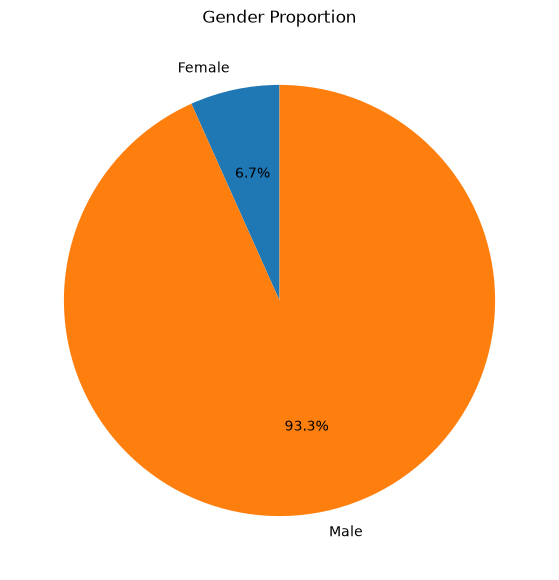

<Figure size 640x480 with 0 Axes>

In [110]:
plt.figure( figsize=(7,7) )


plt.pie(
    x=gender_proportion,
    labels=['Female', "Male"],
    startangle=90,
    autopct="%1.1f%%",
)

plt.title("Gender Proportion")

plt.savefig( 

    VISUALIZATION_SAVE_PATH / "nobel_prize_laureates_gender_proportion.png",
    bbox_inches='tight',
    dpi=300
)


plt.show()

plt.clf()

---

### The top 5 countries by number of Nobel Prize laureates?

In [111]:
laureates_by_country_top5 = df.groupby(['birth_country']).agg(
    count=("birth_country", 'count')
).sort_values( by="count" , ascending=False).head(5)

laureates_by_country_top5

,count
birth_country,
United States of America,291
United Kingdom,91
Germany,86
France,61
Sweden,30


### The category-wise distribution (value count) of Nobel Prize laureates for each of the top 5 countries

first calculating laureates count grouped by **birth_country** and **category**

In [112]:
laureates_by_country_and_category = df.groupby(['birth_country', 'category']).agg(
    count=("birth_country", 'count')
).sort_values( by="count" , ascending=False)


laureates_by_country_and_category


count
birth_country                                 category         
United States of America                      Medicine       80
                                              Physics        70
                                              Chemistry      58
                                              Economics      54
Germany                                       Chemistry      27
...                                                         ...
Turkey                                        Literature      1
Union of Soviet Socialist Republics (Belarus) Physics         1
Venezuela                                     Medicine        1
Vietnam                                       Peace           1
Yemen                                         Peace           1

[236 rows x 1 columns]

then filtering **laureates_by_country_and_category** dataframe, and returning only the top 5 countires with the most laureates

In [113]:
top_5_countries = laureates_by_country_top5.index


laureates_by_country_and_category_top5  = laureates_by_country_and_category.loc[
    laureates_by_country_and_category.index.get_level_values("birth_country")
    .isin(top_5_countries)
]



laureates_by_country_and_category_top5

count
birth_country            category         
United States of America Medicine       80
                         Physics        70
                         Chemistry      58
                         Economics      54
Germany                  Chemistry      27
                         Physics        27
United Kingdom           Medicine       25
                         Chemistry      25
                         Physics        23
United States of America Peace          19
Germany                  Medicine       18
France                   Literature     12
                         Physics        12
                         Medicine       12
                         Chemistry      11
United States of America Literature     10
France                   Peace          10
Germany                  Literature      8
Sweden                   Medicine        8
                         Literature      7
United Kingdom           Economics       7
                         Literature      6
Germany                  Peace           5
United Kingdom           Peace           5
Sweden                   Peace           5
France                   Economics       4
Sweden                   Chemistry       4
                         Physics         4
                         Economics       2
Germany                  Economics       1

after that Sorting the multi-index of **laureates_by_country_and_category_top5** by the **birth_country** level 

In [114]:
laureates_by_country_and_category_top5 = laureates_by_country_and_category_top5.sort_index(level="birth_country")

laureates_by_country_and_category_top5

count
birth_country            category         
France                   Chemistry      11
                         Economics       4
                         Literature     12
                         Medicine       12
                         Peace          10
                         Physics        12
Germany                  Chemistry      27
                         Economics       1
                         Literature      8
                         Medicine       18
                         Peace           5
                         Physics        27
Sweden                   Chemistry       4
                         Economics       2
                         Literature      7
                         Medicine        8
                         Peace           5
                         Physics         4
United Kingdom           Chemistry      25
                         Economics       7
                         Literature      6
                         Medicine       25
                         Peace           5
                         Physics        23
United States of America Chemistry      58
                         Economics      54
                         Literature     10
                         Medicine       80
                         Peace          19
                         Physics        70

changing values of **United States of America** , **United Kingdom** to abbreviated format 

In [115]:
# Rename country labels without corrupting the MultiIndex.
laureates_by_country_and_category_top5 = (
    laureates_by_country_and_category_top5.rename(
        index={
            "United States of America": "USA",
            "United Kingdom": "UK",
        },
        level="birth_country",
    )
)


laureates_by_country_and_category_top5

count
birth_country category         
France        Chemistry      11
              Economics       4
              Literature     12
              Medicine       12
              Peace          10
              Physics        12
Germany       Chemistry      27
              Economics       1
              Literature      8
              Medicine       18
              Peace           5
              Physics        27
Sweden        Chemistry       4
              Economics       2
              Literature      7
              Medicine        8
              Peace           5
              Physics         4
UK            Chemistry      25
              Economics       7
              Literature      6
              Medicine       25
              Peace           5
              Physics        23
USA           Chemistry      58
              Economics      54
              Literature     10
              Medicine       80
              Peace          19
              Physics        70

Visualizing the result using a strip plot

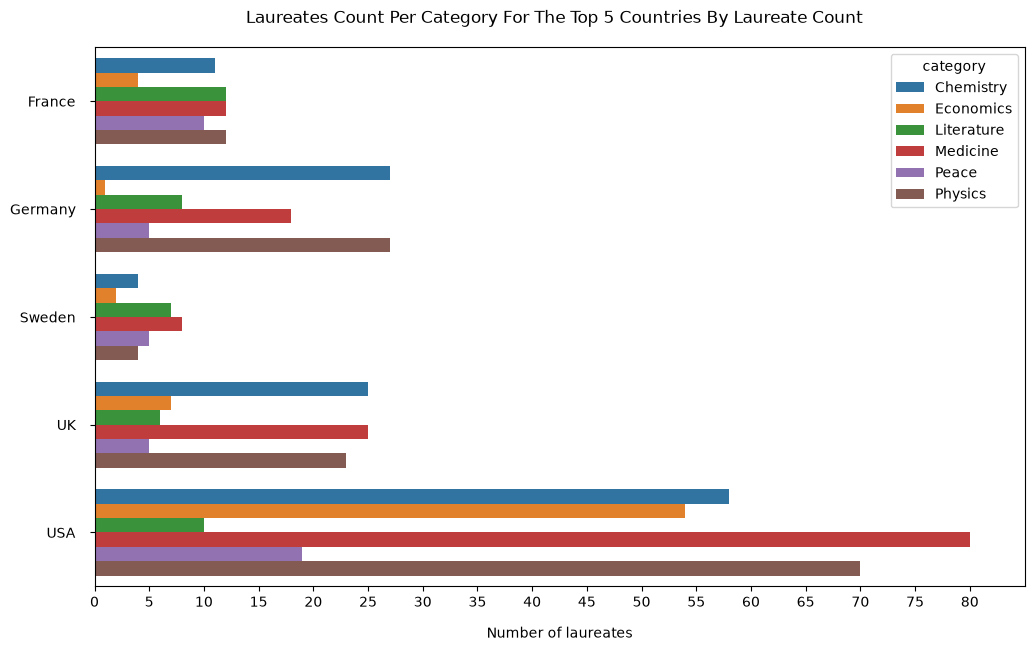

<Figure size 640x480 with 0 Axes>

In [116]:
fig, ax = plt.subplots(figsize=(12,7))

sns.barplot(
    data=laureates_by_country_and_category_top5,
    x="count",
    y=laureates_by_country_and_category_top5.index.get_level_values("birth_country"),
    hue=laureates_by_country_and_category_top5.index.get_level_values("category"),
    ax= ax,

    
)


ax.set_title("Laureate Counts by Prize Category for the Five Countries with the Most Laureates", y=1.03)
ax.set_title("Laureates Count Per Category For The Top 5 Countries By Laureate Count  ", y=1.03)



ax.set_xlim(0,85)
ax.set_xticks(np.arange(0,81,5))
ax.set_xlabel("Number of laureates", labelpad=12)


ax.set_ylabel(None)
ax.tick_params(axis="y", pad=10)


plt.savefig( 
    VISUALIZATION_SAVE_PATH / "Laureates_count_per_category_for_the_top5_countries_by_laureate_count.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.clf()


`Observation`:

* **USA** has the highest number of nobel prize laureats in each category except for the **Literature category**, as **France** has the highest number of Nobel prize for literature laureats

---

### The year with the highest percentage of laureates from the top 5 countries by Nobel Prize laureates

In [117]:
df['is_USA_winner'] = np.where(  df['birth_country']  == "United States of America" , 1 , 0 )

df['is_UK_winner'] = np.where( df['birth_country'] == "United Kingdom", 1 , 0 )

df['is_FRANCE_winner'] = np.where( df['birth_country'] == "France", 1 , 0 )

df['is_GERMANY_winner'] = np.where( df['birth_country'] == "Germany", 1 , 0 )

df['is_SWEDEN_winner'] = np.where( df['birth_country'] == "Sweden", 1 , 0 )


In [118]:
usa_winners_by_year = (
    df.groupby("year")["is_USA_winner"]
      .mean()
      .sort_values(ascending=False)
).mul(100)

print(f"{' ':>8}Percentage")

usa_winners_by_year

        Percentage


year
1946    87.500000
1972    72.727273
1990    72.727273
1934    66.666667
2006    66.666667
          ...    
1917     0.000000
1991     0.000000
1973     0.000000
1963     0.000000
1999     0.000000
Name: is_USA_winner, Length: 120, dtype: float64

In [119]:
uk_winners_by_year = (
    df.groupby('year')['is_UK_winner']
    .mean()
    .sort_values(ascending=False)
).mul(100)


print(f"{' ':>8}Percentage")

uk_winners_by_year

        Percentage


year
1932    60.000000
2016    45.454545
1937    42.857143
1933    40.000000
1922    33.333333
          ...    
2011     0.000000
2014     0.000000
2017     0.000000
2022     0.000000
2023     0.000000
Name: is_UK_winner, Length: 120, dtype: float64

In [120]:
france_winners_by_year = (
    df.groupby('year')['is_FRANCE_winner']
    .mean()
    .sort_values(ascending=False)
).mul(100)


print(f"{' ':>8}Percentage")

france_winners_by_year

        Percentage


year
1912    50.000000
1913    40.000000
1935    40.000000
1901    33.333333
1926    33.333333
          ...    
2011     0.000000
2009     0.000000
2010     0.000000
2017     0.000000
2021     0.000000
Name: is_FRANCE_winner, Length: 120, dtype: float64

In [121]:
germany_winners_by_year = (
    df.groupby('year')['is_GERMANY_winner']
    .mean()
    .sort_values(ascending=False)
).mul(100)


print(f"{' ':>8}Percentage")

germany_winners_by_year.head(10)

        Percentage


year
1918    50.000000
1905    40.000000
1910    40.000000
1935    40.000000
1953    33.333333
1931    33.333333
1925    33.333333
1914    33.333333
1988    33.333333
1971    33.333333
Name: is_GERMANY_winner, dtype: float64

In [122]:
sweden_winners_by_year = (
    df.groupby('year')['is_SWEDEN_winner']
    .mean()
    .sort_values(ascending=False)
).mul(100)


print(f"{' ':>8}Percentage")

sweden_winners_by_year

        Percentage


year
1916    100.000000
1924     33.333333
1982     33.333333
1948     25.000000
1974     25.000000
           ...    
2017      0.000000
2019      0.000000
2020      0.000000
2021      0.000000
2023      0.000000
Name: is_SWEDEN_winner, Length: 120, dtype: float64

`Observations:`

* The year with highest number of laureates born in **USA** is **1946**

* The year with highest number of laureates born in **UK** is **1932**

* The year with highest number of laureates born in **France** is **1912**

* The year with highest number of laureates born in  **Germany** is **1918**

* The year with highest number of laureates born in  **Sweden** is **1916**


---

### The top 5 individuals who have won the most Nobel Prizes

In [123]:
top10_freq_individual =  df[ df['laureate_type' ] == "Individual" ].groupby('laureate_id').agg(
    count=('year', 'count')
).sort_values(ascending=False , by='count').head(n=10)


top10_freq_individual

,count
laureate_id,
66,2
217,2
6,2
743,2
222,2
688,1
686,1
685,1
684,1


`Observation:`

the highest count is two, and it's repeated multiple time, now retrieving the full name of each laureate

In [124]:
names_array = df[  df['laureate_id'].isin( top10_freq_individual.iloc[:5,].index.values ) ]['full_name'].unique()



print("people with the highest nobel awards count: \n")

for i, name in enumerate(names_array) :

    print(f"{i}.{name}")

people with the highest nobel awards count: 

0.Marie Curie, née Sklodowska
1.Linus Carl Pauling
2.John Bardeen
3.Frederick Sanger
4.K. Barry Sharpless
5.Barry Sharpless


### The organization that has been awarded the most Nobel Prizes

In [125]:
df[  df['laureate_type'] == "Organization" ].groupby('laureate_id').agg(
    count=('full_name', "count")
).sort_values(by='count', ascending=False).head(n=10)

,count
laureate_id,
482,3
515,2
467,1
477,1
503,1
508,1
509,1
523,1
525,1


In [126]:
print("The organiation with the most nobel awards count is ( Won 3 ) :\n")

df[ df['laureate_id'] == 482 ]['full_name'].iloc[0]

The organiation with the most nobel awards count is ( Won 3 ) :



'Comité international de la Croix Rouge (International Committee of the Red Cross)'

---

![Thankyou](Thankyou.jpg)